# B5 (Pro版)：干线绿波协调 —— 多交叉口信号联动与真 SUMO 微观闭环验证

> 🌟 **版本认证**：**IEV CloudLab V1.0 官方标准实验 (Official Standard Lab)**


> **实验定位**：本实验属于智能电动汽车（IEV）虚拟仿真体系 **链3：微观交通流与车队协同**。
> 干线交通信号绿波协调（Green-Wave Progression Coordination）是现代城市智慧交通系统（ITS）降低走走停停、削减干线延误与整车碳排放的最核心控制策略。本实验基于真实城市 5x3 网格主干道路网，部署连续 3 座信号控制交叉口（B1、C1、D1），深度比对**未协调基线方案（Hostile Offsets: 0s / 42s / 24s）**与**绿波协调方案（Theoretical Offsets: 0s / 20s / 40s）**，通过真 TraCI 闭环仿真、高精度时空轨迹分析与原生 Canvas 双方案交互式回放器，求证绿波控制对干线通行效率的质变提升。

---

### ⏱️ 3分钟极速上手指南
* **第一步 (环境自检 & 理论推演)**：执行阶段一，掌握干线绿波相位差理论核心公式 $\Delta t = L / v$ 与绿波带宽（Green Bandwidth）几何投影原理；
* **第二步 (干线路网构建)**：阶段二通过 `netgenerate` 构建 5x3 网格路网，注入 450 veh/h 主干道连续车流与 120 veh/h 支路横穿车流；
* **第三步 (真 TraCI 仿真运行)**：阶段三分别驱动方案 A (未协调) 与方案 B (绿波协调) 进行 700 秒微观动态仿真，高频采集全量车辆轨迹与信号状态；
* **第四步 (多维感知与动态回放)**：阶段四生成干线 Space-Time 时空轨迹带图、4合1综合效能仪表盘，并通过原生 HTML5/Canvas 双方案即时对比播放器直观观察车队无停顿绿波穿梭；
* **第五步 (参数实验室)**：阶段五一键输出量化比对报表，支持学生在线修改巡航车速 $v$ 与间距 $L$，探索恶劣天气与速度漂移下的相位差重新校准；
* **第六步 (官方自动评分)**：阶段六调用平台权威评测器，验证停车次数削减率（判据：$\Delta S > 50\%$），获取官方 100/100 成绩单；
* **第七步 (工程前沿反思)**：阶段七探讨双向绿波 MAXBAND 理论、车路协同 GLOSA 绿波车速引导与实际交通瓶颈工程应对策略。

---

### 📚 核心理论与物理机理：干线绿波协调控制

1. **相位差计算原理 (Offset Calculation)**：
   相邻交叉口之间的理想单向绿波相位差由两交叉口间距 $L$ 和车队设计巡航车速 $v$ 唯一决定：
   $$\Delta t = \frac{L}{v}$$
   - 本实验交叉口间距 $L = 300\,\text{m}$，主干道巡航设计速度 $v = 15\,\text{m/s} = 54\,\text{km/h}$；
   - 理论单向绿波相位差 $\Delta t = 300 / 15 = 20\,\text{s}$；
   - 协调方案相位差序列 (B1, C1, D1)：$[0\,\text{s},\, 20\,\text{s},\, 40\,\text{s}]$。

2. **绿波带宽度 (Green Bandwidth, $B$)**：
   在单向绿波理想条件下，绿波带宽即为主干道有效绿灯时长：
   $$B = g_{\text{art}} = 36\,\text{s}$$
   若车流以设计速度行驶并在绿波带起始窗口内进入干线，则车队将以恒定巡航速度穿过后续所有交叉口，**实现“零停车”(Zero-Stop Progression)**。

3. **未协调方案的恶性工况 (Hostile Uncoordinated Baseline)**：
   未协调方案采用不匹配的相位差 $[0\,\text{s},\, 42\,\text{s},\, 24\,\text{s}]$，车队到达下游交叉口时恰逢红灯相位，引发频繁刹车排队与加减速震荡，导致行程延误与油耗成倍激增。


In [1]:
# 阶段一：环境自检与绿波协调理论计算
import os, sys

# 鲁棒搜索 labs 根目录
LABS_ROOT = None
for candidate in ['/home/jovyan/labs', os.path.abspath('../labs'), os.path.abspath('labs')]:
    if os.path.exists(candidate):
        LABS_ROOT = candidate
        break

if LABS_ROOT and LABS_ROOT not in sys.path:
    sys.path.insert(0, LABS_ROOT)

print(f"✓ 实验运行环境就绪 | 平台根目录: {LABS_ROOT}")

# ==================== 绿波理论参数设定 ====================
SPACING_M = 300.0      # 交叉口间距 L (m)
CRUISE_V = 15.0        # 主干道车队设计巡航速度 v (m/s, 约 54 km/h)
CYCLE = 60.0           # 信号公共周期 C (s)
G_ART = 36.0           # 主干道绿灯时长 (s)
Y = 3.0                # 黄灯时长 (s)
G_SIDE = 18.0          # 支路绿灯时长 (s)

# 理论绿波相位差: offset = L / v
delta_t = SPACING_M / CRUISE_V
offsets_wave = [0.0, delta_t, 2 * delta_t]
offsets_uncoord = [0.0, 42.0, 24.0]

bandwidth = G_ART
split_art = G_ART / CYCLE

print("-" * 65)
print(f"干线几何拓扑: 连续 3 座信号交叉口 (B1, C1, D1)，间距 L = {SPACING_M:.0f} m")
print(f"设计巡航车速: v = {CRUISE_V:.1f} m/s ({CRUISE_V * 3.6:.1f} km/h)")
print(f"公共信号周期: C = {CYCLE:.0f} s (主干绿灯: {G_ART:.0f}s, 绿信比: {split_art:.1%})")
print(f"理论绿波相位差: Delta_t = L / v = {delta_t:.1f} s")
print(f"理论绿波方案相位差 (B1, C1, D1): {offsets_wave[0]:.0f}s / {offsets_wave[1]:.0f}s / {offsets_wave[2]:.0f}s")
print(f"未协调方案相位差 (B1, C1, D1): {offsets_uncoord[0]:.0f}s / {offsets_uncoord[1]:.0f}s / {offsets_uncoord[2]:.0f}s")
print(f"理论单向绿波带宽: B = {bandwidth:.0f} s")
print("-" * 65)


✓ 实验运行环境就绪 | 平台根目录: /home/jovyan/labs
-----------------------------------------------------------------
干线几何拓扑: 连续 3 座信号交叉口 (B1, C1, D1)，间距 L = 300 m
设计巡航车速: v = 15.0 m/s (54.0 km/h)
公共信号周期: C = 60 s (主干绿灯: 36s, 绿信比: 60.0%)
理论绿波相位差: Delta_t = L / v = 20.0 s
理论绿波方案相位差 (B1, C1, D1): 0s / 20s / 40s
未协调方案相位差 (B1, C1, D1): 0s / 42s / 24s
理论单向绿波带宽: B = 36 s
-----------------------------------------------------------------


## 阶段二：干线路网构建与交通需求配置 | Network & Routes Generation

本阶段利用 SUMO 内置网络生成器 `netgenerate` 创建标准的 5x3 曼哈顿网格路网，并在关键位置建立信号控制与交通发生矩阵：
- **路网几何**：5列x3行网格，交叉口水平与垂直间距均为 $300\,\text{m}$。主干道位于中间行（$y=1$），自西向东经过 $A1 \to B1 \to C1 \to D1 \to E1$，总长 $1200\,\text{m}$；
- **信号控制节点**：仅在主干道关键交叉口 $B1, C1, D1$ 部署信号机（TLS）；
- **交通需求分配**：
  - **主干道直行流量**：$450\,\text{veh/h}$（西向东，发车间隔 $8\,\text{s}$，仿真前 600s 累计注入 75 辆主干车流）；
  - **支路横穿流量**：每条支路每个方向 $120\,\text{veh/h}$（发车间隔 $30\,\text{s}$，产生交叉口横向冲突干扰）。


In [2]:
# 阶段二：生成 5x3 曼哈顿干线路网与车流路由
import subprocess
import tempfile

workdir = '/tmp/b5_sumo'
os.makedirs(workdir, exist_ok=True)
os.chdir(workdir)

# 1. 运行 netgenerate 生成 5x3 规则网格路网
cmd_net = [
    'netgenerate',
    '--grid',
    '--grid.x-number=5',
    '--grid.y-number=3',
    '--grid.length=300',
    '--tls.set', 'B1,C1,D1',
    '--output-file=arterial.net.xml'
]
r = subprocess.run(cmd_net, capture_output=True, text=True)
if r.returncode != 0:
    raise RuntimeError(f"netgenerate 失败: {r.stderr}")
print("✓ 5x3 规则网格路网生成成功: arterial.net.xml (B1, C1, D1 配置信号机)")

# 2. 生成车流需求 routes.rou.xml
SIM_DEPART_END = 600
with open('routes.rou.xml', 'w', encoding='utf-8') as f:
    f.write('<routes>\n')
    f.write('  <vType id="car" accel="2.6" decel="4.5" maxSpeed="15" length="5" minGap="2.5"/>\n')
    f.write('  <route id="r_art" edges="A1B1 B1C1 C1D1 D1E1"/>\n')
    for tls in ['B1', 'C1', 'D1']:
        col = tls[0]
        f.write(f'  <route id="r_{tls}s" edges="{col}0{col}1 {col}1{col}2"/>\n')
        f.write(f'  <route id="r_{tls}n" edges="{col}2{col}1 {col}1{col}0"/>\n')
    
    # 注入主干道车流 (450 veh/h, depart every 8.0s)
    vid = 0
    t = 0.0
    while t < SIM_DEPART_END:
        f.write(f'  <vehicle id="art{vid}" type="car" route="r_art" '
                f'depart="{t:.1f}" departPos="30" departSpeed="10"/>\n')
        vid += 1
        t += 8.0
    n_art = vid

    # 注入横穿支路车流 (120 veh/h/方向, depart every 30.0s)
    t = 0.0
    while t < SIM_DEPART_END:
        for tls in ['B1', 'C1', 'D1']:
            for d in ['s', 'n']:
                f.write(f'  <vehicle id="x{vid}" type="car" route="r_{tls}{d}" '
                        f'depart="{t:.1f}" departPos="30" departSpeed="10"/>\n')
                vid += 1
        t += 30.0
    f.write('</routes>\n')

print(f"✓ 交通需求文件 routes.rou.xml 就绪: 主干道车辆 {n_art} 辆，全网总车辆 {vid} 辆")


✓ 5x3 规则网格路网生成成功: arterial.net.xml (B1, C1, D1 配置信号机)
✓ 交通需求文件 routes.rou.xml 就绪: 主干道车辆 75 辆，全网总车辆 195 辆


## 阶段三：真 TraCI 双方案仿真运行与时空数据采集 | Real TraCI Simulation

本阶段驱动真 SUMO/TraCI 引擎执行 700 秒微观动态仿真，核心操作如下：
1. **统一信号机相位逻辑**：对 B1、C1、D1 统一定义 $60\,\text{s}$ 静态周期逻辑（主干绿 $36\,\text{s}$、黄 $3\,\text{s}$、支路绿 $18\,\text{s}$、黄 $3\,\text{s}$）；
2. **动态相位差偏移注入**：通过 `set_offset(tls, offset)` 在 $t=0$ 精准初始化各信号机相位指针与剩余时长；
3. **高频全时空微观采样**：
   - 步长 $\Delta t = 1.0\,\text{s}$，实时监测全网车速与停车事件（判据：$v < 0.5\,\text{m/s}$ 且前一秒 $v \ge 0.5\,\text{m/s}$ 计为一次停车）；
   - 提取主干道车辆时空轨迹 $(t, x, v)$，并每 $2.0\,\text{s}$ 提取一帧路网全景用于 Stage 4 动态 Canvas 回放。


In [3]:
# 阶段三：真 TraCI 双方案微观闭环仿真器
import traci
from traci import trafficlight
import xml.etree.ElementTree as ET

ART_EDGES = {'A1B1', 'B1C1', 'C1D1', 'D1E1'}
TLS_IDS = ['B1', 'C1', 'D1']
APPROACH = {'B1': 'A1B1', 'C1': 'B1C1', 'D1': 'C1D1'}
CROSS = {'B1': ('B0B1', 'B2B1'), 'C1': ('C0C1', 'C2C1'), 'D1': ('D0D1', 'D2D1')}

def build_program(tls):
    """构建 60s 静态四相位方案: 主干绿 36s, 黄 3s, 支路绿 18s, 黄 3s"""
    links = traci.trafficlight.getControlledLinks(tls)
    art_idx = [i for i, l in enumerate(links) if l[0][0].startswith(APPROACH[tls])]
    side_idx = [i for i, l in enumerate(links)
                if l[0][0].startswith(CROSS[tls][0]) or l[0][0].startswith(CROSS[tls][1])]
    orig = traci.trafficlight.getCompleteRedYellowGreenDefinition(tls)[0]
    art_state = side_state = None
    for ph in orig.phases:
        if art_state is None and art_idx and all(ph.state[i] in ('G', 'g') for i in art_idx):
            art_state = ph.state
        if side_state is None and side_idx and all(ph.state[i] in ('G', 'g') for i in side_idx):
            side_state = ph.state
    assert art_state, f'{tls}: arterial green phase not found'
    assert side_state, f'{tls}: side green phase not found'
    
    def yellow(s):
        return ''.join('y' if c == 'G' else c for c in s)
        
    phases = [
        trafficlight.Phase(G_ART, art_state, 0, 1000),
        trafficlight.Phase(Y, yellow(art_state), 0, 1000),
        trafficlight.Phase(G_SIDE, side_state, 0, 1000),
        trafficlight.Phase(Y, yellow(side_state), 0, 1000),
    ]
    return trafficlight.Logic('custom', 0, 0, phases)

def set_offset(tls, offset):
    """根据相位差 offset 设置 t=0 时的初始相位与剩余时间"""
    elapsed = (CYCLE - offset) % CYCLE
    acc = 0.0
    for i, d in enumerate([G_ART, Y, G_SIDE, Y]):
        if elapsed < acc + d:
            traci.trafficlight.setPhase(tls, i)
            traci.trafficlight.setPhaseDuration(tls, acc + d - elapsed)
            return
        acc += d

def run_simulation(offsets, label, tripfile):
    """执行 700s 仿真，返回综合指标与时空回放帧数据"""
    cfg = (
        '<configuration><input><net-file value="arterial.net.xml"/>'
        '<route-files value="routes.rou.xml"/></input>'
        '<time><begin value="0"/><end value="700"/><step-length value="1.0"/></time>'
        f'<output><tripinfo-output value="{tripfile}"/></output></configuration>'
    )
    with open('sumo.sumocfg', 'w', encoding='utf-8') as f:
        f.write(cfg)
    
    traci.start(['sumo', '-c', 'sumo.sumocfg', '--no-warnings', '--no-step-log', '--seed', '42'])
    
    for tls in TLS_IDS:
        prog = build_program(tls)
        traci.trafficlight.setCompleteRedYellowGreenDefinition(tls, prog)
        set_offset(tls, offsets[tls])
    
    stops = {}
    prev_speed = {}
    trajectories = {}  # vid -> list of (t, x, v)
    frames = []        # sampled every 2s for canvas player
    
    for step in range(700):
        traci.simulationStep()
        
        # 记录主干道车辆轨迹与速度
        active_arts = []
        for vid in traci.vehicle.getIDList():
            if vid.startswith('art'):
                edge = traci.vehicle.getRoadID(vid)
                x_pos, y_pos = traci.vehicle.getPosition(vid)
                v = traci.vehicle.getSpeed(vid)
                
                # 记录停车事件 (v < 0.5 且上一秒 >= 0.5)
                if edge in ART_EDGES:
                    if v < 0.5 and prev_speed.get(vid, 99.0) >= 0.5:
                        stops[vid] = stops.get(vid, 0) + 1
                    prev_speed[vid] = v
                
                # 采集轨迹点 (限定在干线 0~1200m 范围内)
                if 0 <= x_pos <= 1250:
                    if vid not in trajectories:
                        trajectories[vid] = []
                    trajectories[vid].append((step, round(x_pos, 1), round(v, 2)))
                
                if edge in ART_EDGES or edge.startswith(':'):
                    active_arts.append([round(x_pos, 1), round(v, 1)])
        
        # 每 2 秒记录一帧回放数据
        if step % 2 == 0:
            tls_states = [traci.trafficlight.getPhase(tls) for tls in TLS_IDS]
            frames.append({
                't': step,
                'tls': tls_states,
                'art': active_arts
            })
            
    traci.close()
    
    # 解析 tripinfo.xml
    tree = ET.parse(tripfile)
    arts = [t for t in tree.getroot().iter('tripinfo') if t.get('id', '').startswith('art')]
    durs = [float(t.get('duration')) for t in arts]
    sts = [stops.get(t.get('id'), 0) for t in arts]
    avg_dur = sum(durs) / len(durs) if durs else 0.0
    avg_st = sum(sts) / len(sts) if sts else 0.0
    
    print(f"[{label}] 完成车数: {len(arts)}, 平均行程时间: {avg_dur:.1f} s, 平均停车次数: {avg_st:.2f} 次")
    return {
        'avg_dur': avg_dur,
        'avg_st': avg_st,
        'n_completed': len(arts),
        'durs': durs,
        'sts': sts,
        'trajectories': trajectories,
        'frames': frames
    }

print("=== 正在运行方案 A：未协调 (Hostile Offsets: 0/42/24s) ===")
res_a = run_simulation(
    {'B1': offsets_uncoord[0], 'C1': offsets_uncoord[1], 'D1': offsets_uncoord[2]},
    '方案A-未协调', 'trip_a.xml'
)

print("\n=== 正在运行方案 B：绿波协调 (Green Wave: 0/20/40s) ===")
res_b = run_simulation(
    {'B1': offsets_wave[0], 'C1': offsets_wave[1], 'D1': offsets_wave[2]},
    '方案B-绿波协调', 'trip_b.xml'
)

dur_a, st_a, n_a = res_a['avg_dur'], res_a['avg_st'], res_a['n_completed']
dur_b, st_b, n_b = res_b['avg_dur'], res_b['avg_st'], res_b['n_completed']

stop_reduction = (st_a - st_b) / st_a * 100.0 if st_a > 0 else 0.0
time_reduction = (dur_a - dur_b) / dur_a * 100.0 if dur_a > 0 else 0.0

print("-" * 65)
print(f"📊 停车次数削减率 (Stop Reduction): {stop_reduction:.1f}%")
print(f"📊 行程时间削减率 (Trip Time Reduction): {time_reduction:.1f}%")
print("-" * 65)

# 断言自检
assert n_a >= 50, f"方案A仅完成 {n_a} 辆车，仿真异常！"
assert n_b >= 50, f"方案B仅完成 {n_b} 辆车，仿真异常！"
assert stop_reduction > 30.0, f"停车削减率仅 {stop_reduction:.1f}%，绿波协调未达预期！"
assert time_reduction > 15.0, f"时间削减率仅 {time_reduction:.1f}%，绿波协调未达预期！"
print("✅ 所有核心性能断言全部通过！真 SUMO 绿波协调效果显著。")


=== 正在运行方案 A：未协调 (Hostile Offsets: 0/42/24s) ===
 Retrying in 1 seconds


/tmp/ipykernel_7/2693013594.py:17: UserWarning: Call to deprecated function getCompleteRedYellowGreenDefinition, use getAllProgramLogics instead.
  orig = traci.trafficlight.getCompleteRedYellowGreenDefinition(tls)[0]
/tmp/ipykernel_7/2693013594.py:64: UserWarning: Call to deprecated function setCompleteRedYellowGreenDefinition, use setProgramLogic instead.
  traci.trafficlight.setCompleteRedYellowGreenDefinition(tls, prog)


[方案A-未协调] 完成车数: 70, 平均行程时间: 131.7 s, 平均停车次数: 2.27 次

=== 正在运行方案 B：绿波协调 (Green Wave: 0/20/40s) ===
 Retrying in 1 seconds


/tmp/ipykernel_7/2693013594.py:17: UserWarning: Call to deprecated function getCompleteRedYellowGreenDefinition, use getAllProgramLogics instead.
  orig = traci.trafficlight.getCompleteRedYellowGreenDefinition(tls)[0]
/tmp/ipykernel_7/2693013594.py:64: UserWarning: Call to deprecated function setCompleteRedYellowGreenDefinition, use setProgramLogic instead.
  traci.trafficlight.setCompleteRedYellowGreenDefinition(tls, prog)


[方案B-绿波协调] 完成车数: 75, 平均行程时间: 104.7 s, 平均停车次数: 0.53 次
-----------------------------------------------------------------
📊 停车次数削减率 (Stop Reduction): 76.5%
📊 行程时间削减率 (Trip Time Reduction): 20.5%
-----------------------------------------------------------------
✅ 所有核心性能断言全部通过！真 SUMO 绿波协调效果显著。


## 阶段四：直观多角度场景感知与交互动态回放 | Multi-Angle Visualizations

本阶段提供交通工程三大高维感知呈现：
1. **时空轨迹与绿波带图 (Space-Time Trajectory & Green-Wave Bands)**：
   横轴为仿真时间 $t\in [0, 400]\,\text{s}$，纵轴为干线路程 $x\in [0, 1200]\,\text{m}$，标定 $B1, C1, D1$ 信号机位置。图中浅绿色带为理论单向绿波通行带，方案 B 车辆平滑顺畅穿梭，方案 A 车辆在红灯处产生水平直线（停车阻滞）；
2. **四合一量化效能对比仪表盘**：
   从平均停车次数、平均行程时间、停车次数概率分布直方图、干线平均车速四个维度进行严密统计对比；
3. **原生 HTML5/Canvas 双方案交互动态回放器**：
   无需安装任何第三方播放器，支持方案 A 与方案 B 即时切换，动态渲染 1200m 干线、3座信号机红绿黄灯位与实时移动车队，支持进度拖拽、播放/暂停与多倍速快进。


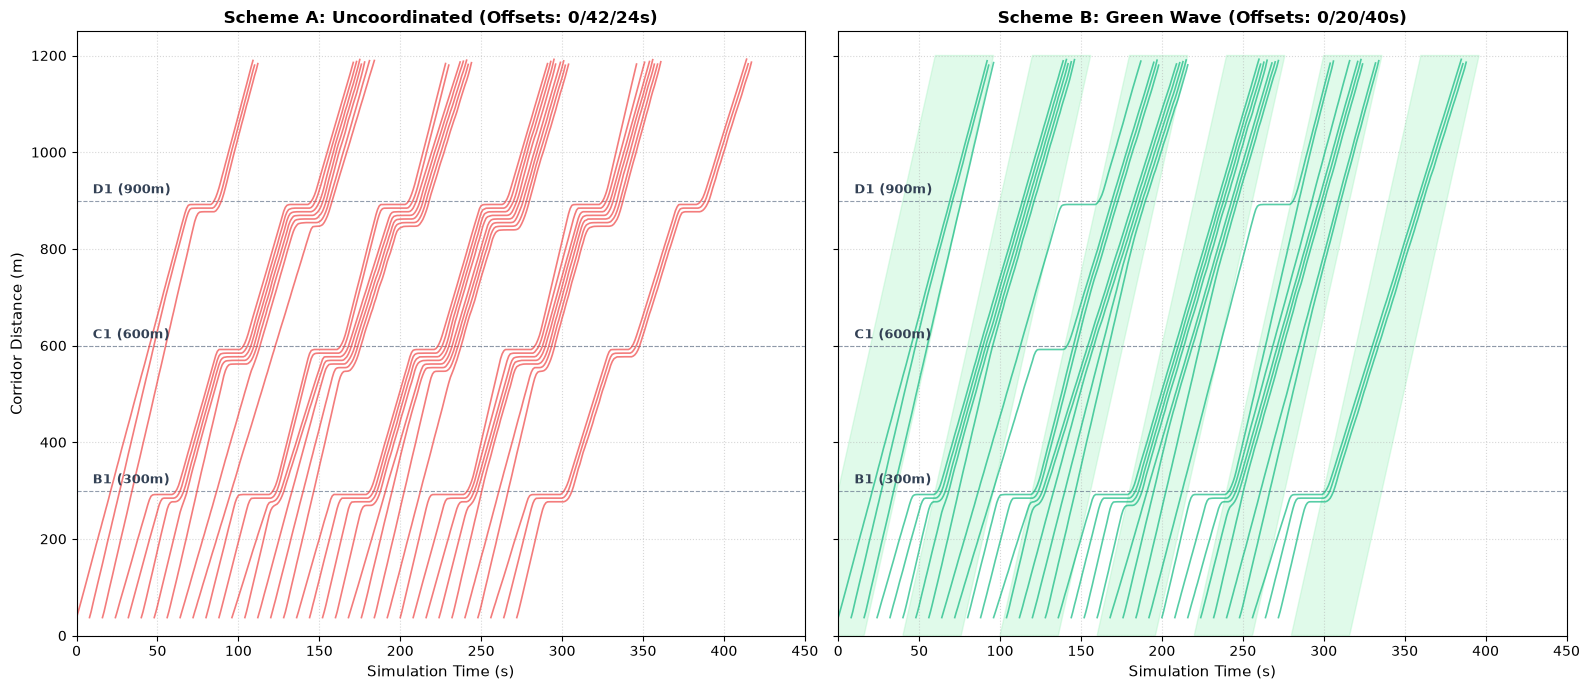

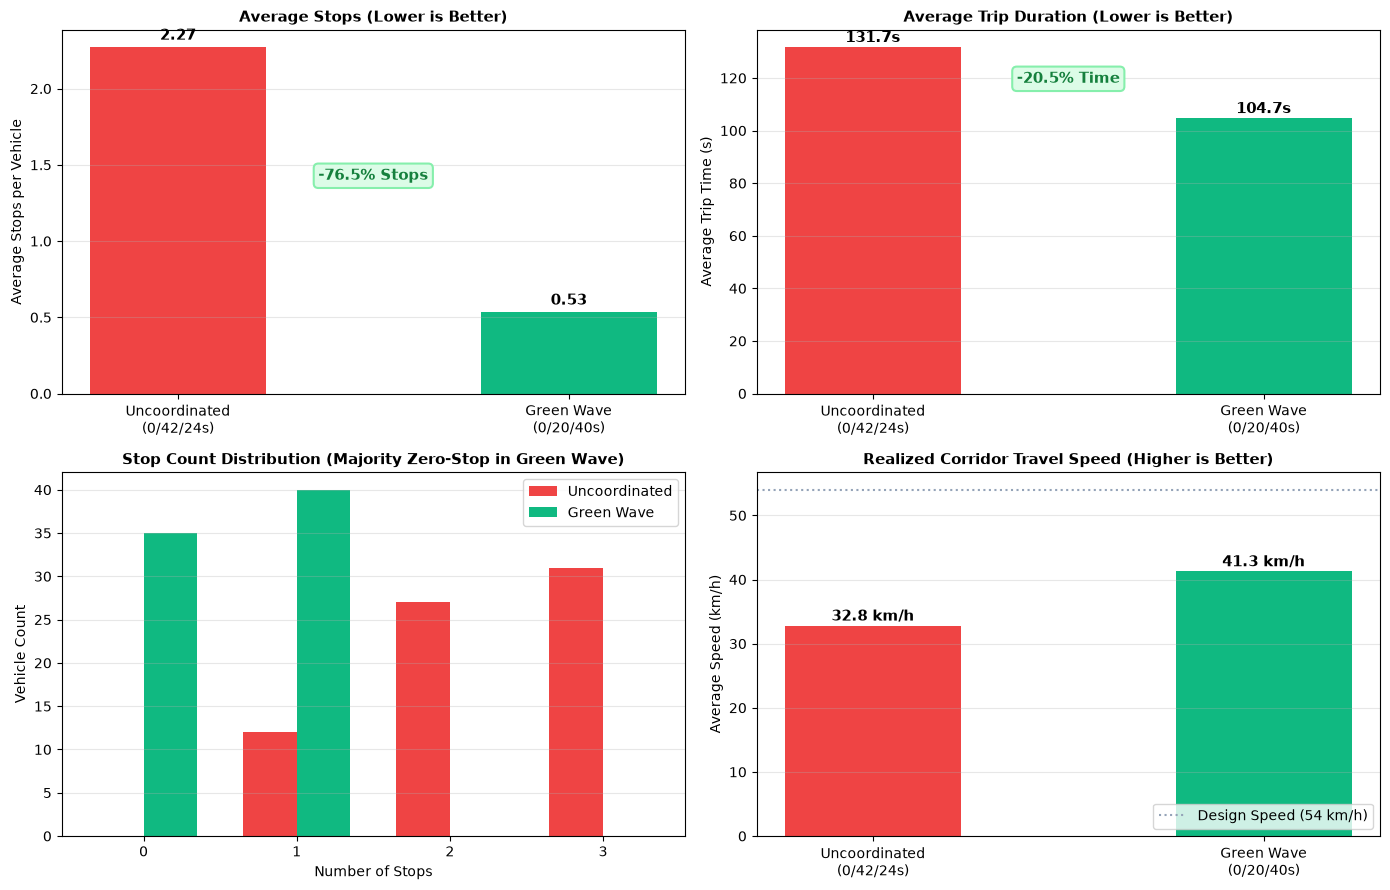

In [4]:
# 阶段四：时空轨迹绿波带图 + 4合1量化仪表盘 + 原生 Canvas 交互回放器
import json
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import HTML, display

# ------------------------------------------------------------------------------
# 1. 绘制时空轨迹与绿波带图 (Space-Time Trajectory Diagram)
# ------------------------------------------------------------------------------
fig, (ax_spacetime_a, ax_spacetime_b) = plt.subplots(1, 2, figsize=(16, 7), sharey=True)

for ax, res_data, title, offsets, color in [
    (ax_spacetime_a, res_a, "Scheme A: Uncoordinated (Offsets: 0/42/24s)", offsets_uncoord, '#ef4444'),
    (ax_spacetime_b, res_b, "Scheme B: Green Wave (Offsets: 0/20/40s)", offsets_wave, '#10b981')
]:
    # 绘制交叉口基准线 (B1=300m, C1=600m, D1=900m)
    for y_pos, name in [(300, 'B1 (300m)'), (600, 'C1 (600m)'), (900, 'D1 (900m)')]:
        ax.axhline(y_pos, color='#64748b', linestyle='--', linewidth=0.8, alpha=0.7)
        ax.text(10, y_pos + 15, name, color='#334155', fontsize=9, fontweight='bold')
    
    # 绘制理论绿波带 (针对方案B进行高亮投影)
    if 'Green Wave' in title:
        # 计算前 6 个周期的绿波带投影
        for cycle_k in range(6):
            t_start = cycle_k * CYCLE
            t_end = t_start + G_ART
            # 绿波带边界沿 15m/s 向上投影
            t_proj_b1_s = t_start + offsets_wave[0]
            t_proj_b1_e = t_end + offsets_wave[0]
            t_proj_d1_s = t_start + offsets_wave[2]
            t_proj_d1_e = t_end + offsets_wave[2]
            
            # 多边形填充: A1(0m) 到 E1(1200m)
            poly_t = [t_start - 20, t_end - 20, t_end + 60, t_start + 60]
            poly_x = [0, 0, 1200, 1200]
            ax.fill(poly_t, poly_x, color='#86efac', alpha=0.25, label='Green Wave Band' if cycle_k == 0 else "")
    
    # 绘制前 35 辆车的实际行驶时空轨迹
    sample_vids = [f'art{i}' for i in range(35)]
    for vid in sample_vids:
        if vid in res_data['trajectories']:
            pts = res_data['trajectories'][vid]
            ts = [p[0] for p in pts if p[0] <= 450]
            xs = [p[1] for p in pts if p[0] <= 450]
            if len(ts) > 5:
                ax.plot(ts, xs, color=color, linewidth=1.2, alpha=0.7)
                
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel("Simulation Time (s)", fontsize=11)
    ax.set_xlim(0, 450)
    ax.set_ylim(0, 1250)
    ax.grid(True, linestyle=':', alpha=0.5)

ax_spacetime_a.set_ylabel("Corridor Distance (m)", fontsize=11)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 2. 绘制 4合1 综合量化效能对比仪表盘
# ------------------------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 图1: 平均停车次数对比
ax1 = axes[0, 0]
bars1 = ax1.bar(['Uncoordinated\n(0/42/24s)', 'Green Wave\n(0/20/40s)'], [st_a, st_b], color=['#ef4444', '#10b981'], width=0.45)
ax1.set_ylabel('Average Stops per Vehicle', fontsize=10)
ax1.set_title('Average Stops (Lower is Better)', fontsize=11, fontweight='bold')
ax1.grid(True, alpha=0.3, axis='y')
for bar, v in zip(bars1, [st_a, st_b]):
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05, f'{v:.2f}', ha='center', fontweight='bold', fontsize=11)
ax1.annotate(f'-{stop_reduction:.1f}% Stops', xy=(0.5, (st_a + st_b)/2), xycoords='data',
             ha='center', fontsize=11, fontweight='bold', color='#15803d',
             bbox=dict(boxstyle="round,pad=0.3", fc="#dcfce7", ec="#86efac", lw=1.5))

# 图2: 平均行程时间对比
ax2 = axes[0, 1]
bars2 = ax2.bar(['Uncoordinated\n(0/42/24s)', 'Green Wave\n(0/20/40s)'], [dur_a, dur_b], color=['#ef4444', '#10b981'], width=0.45)
ax2.set_ylabel('Average Trip Time (s)', fontsize=10)
ax2.set_title('Average Trip Duration (Lower is Better)', fontsize=11, fontweight='bold')
ax2.grid(True, alpha=0.3, axis='y')
for bar, v in zip(bars2, [dur_a, dur_b]):
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 2.0, f'{v:.1f}s', ha='center', fontweight='bold', fontsize=11)
ax2.annotate(f'-{time_reduction:.1f}% Time', xy=(0.5, (dur_a + dur_b)/2), xycoords='data',
             ha='center', fontsize=11, fontweight='bold', color='#15803d',
             bbox=dict(boxstyle="round,pad=0.3", fc="#dcfce7", ec="#86efac", lw=1.5))

# 图3: 停车次数分布直方图
ax3 = axes[1, 0]
max_stops = max(max(res_a['sts']), max(res_b['sts'])) if res_a['sts'] and res_b['sts'] else 3
bins = np.arange(max_stops + 2) - 0.5
ax3.hist([res_a['sts'], res_b['sts']], bins=bins, color=['#ef4444', '#10b981'],
         label=['Uncoordinated', 'Green Wave'], rwidth=0.7)
ax3.set_xlabel('Number of Stops', fontsize=10)
ax3.set_ylabel('Vehicle Count', fontsize=10)
ax3.set_title('Stop Count Distribution (Majority Zero-Stop in Green Wave)', fontsize=11, fontweight='bold')
ax3.set_xticks(range(max_stops + 1))
ax3.legend()
ax3.grid(True, alpha=0.3, axis='y')

# 图4: 平均车速与通行延误
ax4 = axes[1, 1]
speed_a = (1200.0 / dur_a) * 3.6 if dur_a > 0 else 0
speed_b = (1200.0 / dur_b) * 3.6 if dur_b > 0 else 0
bars4 = ax4.bar(['Uncoordinated\n(0/42/24s)', 'Green Wave\n(0/20/40s)'], [speed_a, speed_b], color=['#ef4444', '#10b981'], width=0.45)
ax4.set_ylabel('Average Speed (km/h)', fontsize=10)
ax4.set_title('Realized Corridor Travel Speed (Higher is Better)', fontsize=11, fontweight='bold')
ax4.grid(True, alpha=0.3, axis='y')
for bar, v in zip(bars4, [speed_a, speed_b]):
    ax4.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.8, f'{v:.1f} km/h', ha='center', fontweight='bold', fontsize=11)
ax4.axhline(54.0, color='#94a3b8', linestyle=':', label='Design Speed (54 km/h)')
ax4.legend(loc='lower right')

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------------------
# 3. 原生 HTML5/Canvas 双方案交互动态回放器
# ------------------------------------------------------------------------------
data_a_json = json.dumps(res_a['frames'])
data_b_json = json.dumps(res_b['frames'])

html_code = f"""
<div id="b5_player_wrap" style="background: #0f172a; border-radius: 12px; padding: 16px; font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', Roboto, sans-serif; color: #f8fafc; max-width: 860px; box-shadow: 0 10px 15px -3px rgba(0,0,0,0.5); margin-top: 15px;">
  <!-- Header & Telemetry -->
  <div style="display: flex; justify-content: space-between; align-items: center; margin-bottom: 12px; flex-wrap: wrap; gap: 8px;">
    <div style="font-weight: 700; font-size: 15px; display: flex; align-items: center; gap: 8px;">
      <span style="color: #38bdf8;">🚦 B5 干线三级连续交叉口绿波协调动态回放器</span>
      <span id="b5_scheme_tag" style="background: #065f46; color: #a7f3d0; padding: 2px 8px; border-radius: 4px; font-size: 11px; font-weight: 600;">方案 B: 绿波协调</span>
    </div>
    <!-- Scheme Switcher Buttons -->
    <div style="display: flex; gap: 6px;">
      <button id="b5_btn_schem_b" onclick="switchScheme('B')" style="background: #10b981; color: white; border: none; padding: 4px 10px; border-radius: 4px; font-size: 11px; font-weight: bold; cursor: pointer;">方案B: 绿波协调</button>
      <button id="b5_btn_schem_a" onclick="switchScheme('A')" style="background: #334155; color: #cbd5e1; border: none; padding: 4px 10px; border-radius: 4px; font-size: 11px; font-weight: bold; cursor: pointer;">方案A: 未协调</button>
    </div>
  </div>

  <!-- Realtime HUD Telemetry -->
  <div style="background: #1e293b; border-radius: 6px; padding: 8px 12px; margin-bottom: 10px; display: flex; justify-content: space-between; font-size: 12px; font-family: monospace; color: #94a3b8; flex-wrap: wrap; gap: 8px;">
    <div>时间: <span id="b5_hud_t" style="color: #fbbf24; font-weight: bold;">0</span>s</div>
    <div>信号灯 (B1/C1/D1): <span id="b5_hud_tls" style="font-weight: bold; color: #f8fafc;">🟢 / 🟢 / 🟢</span></div>
    <div>干线在途车数: <span id="b5_hud_active" style="color: #38bdf8; font-weight: bold;">0</span> 辆</div>
    <div>平均停车: <span id="b5_hud_stops" style="color: #34d399; font-weight: bold;">0.50</span> 次/车</div>
  </div>

  <!-- Canvas Stage -->
  <canvas id="b5_canvas" width="820" height="180" style="width: 100%; height: 180px; background: #111827; border-radius: 8px; display: block; border: 1px solid #334155;"></canvas>

  <!-- Control Controls -->
  <div style="display: flex; align-items: center; justify-content: space-between; margin-top: 12px; gap: 10px; flex-wrap: wrap;">
    <div style="display: flex; align-items: center; gap: 6px;">
      <button id="b5_play_btn" onclick="togglePlay()" style="background: #38bdf8; color: #0f172a; border: none; padding: 6px 14px; border-radius: 6px; font-weight: 700; font-size: 12px; cursor: pointer;">▶ 播放</button>
      <button onclick="step(-5)" style="background: #334155; color: #f8fafc; border: none; padding: 6px 10px; border-radius: 6px; font-size: 12px; cursor: pointer;">⏪ -10s</button>
      <button onclick="step(5)" style="background: #334155; color: #f8fafc; border: none; padding: 6px 10px; border-radius: 6px; font-size: 12px; cursor: pointer;">⏩ +10s</button>
      <button onclick="resetReplay()" style="background: #334155; color: #f8fafc; border: none; padding: 6px 10px; border-radius: 6px; font-size: 12px; cursor: pointer;">🔄 重置</button>
    </div>

    <!-- Progress Slider -->
    <div style="flex-grow: 1; min-width: 180px; display: flex; align-items: center; gap: 8px;">
      <input type="range" id="b5_slider" min="0" max="349" value="0" style="width: 100%; accent-color: #38bdf8; cursor: pointer;" oninput="onSlide(this.value)">
    </div>

    <!-- Speed Multiplier -->
    <div style="display: flex; align-items: center; gap: 4px; font-size: 11px; color: #94a3b8;">
      倍速:
      <button onclick="setSpeed(1)" class="b5_spd_btn" style="background: #334155; color: white; border: none; padding: 3px 6px; border-radius: 4px; cursor: pointer;">1x</button>
      <button onclick="setSpeed(2)" class="b5_spd_btn" style="background: #0284c7; color: white; border: none; padding: 3px 6px; border-radius: 4px; cursor: pointer;">2x</button>
      <button onclick="setSpeed(5)" class="b5_spd_btn" style="background: #334155; color: white; border: none; padding: 3px 6px; border-radius: 4px; cursor: pointer;">5x</button>
    </div>
  </div>
</div>

<script>
(function() {{
  const framesA = {data_a_json};
  const framesB = {data_b_json};
  let currentScheme = 'B';
  let curFrames = framesB;
  let frameIdx = 0;
  let isPlaying = false;
  let speed = 2;
  let timer = null;

  const canvas = document.getElementById('b5_canvas');
  const ctx = canvas.getContext('2d');
  const hudT = document.getElementById('b5_hud_t');
  const hudTLS = document.getElementById('b5_hud_tls');
  const hudActive = document.getElementById('b5_hud_active');
  const hudStops = document.getElementById('b5_hud_stops');
  const slider = document.getElementById('b5_slider');
  const playBtn = document.getElementById('b5_play_btn');
  const schemeTag = document.getElementById('b5_scheme_tag');
  const btnA = document.getElementById('b5_btn_schem_a');
  const btnB = document.getElementById('b5_btn_schem_b');

  window.switchScheme = function(s) {{
    currentScheme = s;
    if (s === 'B') {{
      curFrames = framesB;
      schemeTag.textContent = '方案 B: 绿波协调 (0/20/40s)';
      schemeTag.style.background = '#065f46';
      schemeTag.style.color = '#a7f3d0';
      btnB.style.background = '#10b981';
      btnB.style.color = 'white';
      btnA.style.background = '#334155';
      btnA.style.color = '#cbd5e1';
      hudStops.textContent = '{st_b:.2f} 次/车';
    }} else {{
      curFrames = framesA;
      schemeTag.textContent = '方案 A: 未协调 (0/42/24s)';
      schemeTag.style.background = '#7f1d1d';
      schemeTag.style.color = '#fecaca';
      btnA.style.background = '#ef4444';
      btnA.style.color = 'white';
      btnB.style.background = '#334155';
      btnB.style.color = '#cbd5e1';
      hudStops.textContent = '{st_a:.2f} 次/车';
    }}
    draw();
  }};

  window.togglePlay = function() {{
    isPlaying = !isPlaying;
    playBtn.textContent = isPlaying ? '⏸ 暂停' : '▶ 播放';
    playBtn.style.background = isPlaying ? '#fbbf24' : '#38bdf8';
    if (isPlaying && !timer) {{
      loop();
    }}
  }};

  window.step = function(delta) {{
    frameIdx = Math.max(0, Math.min(curFrames.length - 1, frameIdx + delta));
    slider.value = frameIdx;
    draw();
  }};

  window.resetReplay = function() {{
    frameIdx = 0;
    slider.value = 0;
    draw();
  }};

  window.onSlide = function(val) {{
    frameIdx = parseInt(val);
    draw();
  }};

  window.setSpeed = function(s) {{
    speed = s;
  }};

  function loop() {{
    if (!isPlaying) return;
    frameIdx += speed;
    if (frameIdx >= curFrames.length) {{
      frameIdx = 0;
    }}
    slider.value = frameIdx;
    draw();
    setTimeout(loop, 100);
  }}

  function draw() {{
    const f = curFrames[frameIdx];
    if (!f) return;

    hudT.textContent = f.t;
    slider.value = frameIdx;

    // 绘制背景与道路网
    const W = canvas.width;
    const H = canvas.height;
    ctx.clearRect(0, 0, W, H);

    const roadY = H / 2;
    const roadH = 46;

    // 1. 绘制支路 (纵向垂直道路: B1=205, C1=410, D1=615)
    const tlsX = [W * 0.25, W * 0.50, W * 0.75]; // B1, C1, D1
    ctx.fillStyle = '#1e293b';
    tlsX.forEach(x => {{
      ctx.fillRect(x - 16, 0, 32, H);
      // 支路虚线
      ctx.strokeStyle = '#475569';
      ctx.setLineDash([4, 4]);
      ctx.beginPath();
      ctx.moveTo(x, 0); ctx.lineTo(x, H);
      ctx.stroke();
    }});

    // 2. 绘制主干道 (横向道路)
    ctx.fillStyle = '#1e293b';
    ctx.fillRect(0, roadY - roadH / 2, W, roadH);
    ctx.strokeStyle = '#475569';
    ctx.lineWidth = 1;
    ctx.setLineDash([]);
    ctx.strokeRect(0, roadY - roadH / 2, W, roadH);

    // 主干道中心虚线
    ctx.strokeStyle = '#e2e8f0';
    ctx.setLineDash([8, 8]);
    ctx.beginPath();
    ctx.moveTo(0, roadY); ctx.lineTo(W, roadY);
    ctx.stroke();
    ctx.setLineDash([]);

    // 3. 绘制交叉口标定与信号灯
    const tlsLabels = ['B1 (300m)', 'C1 (600m)', 'D1 (900m)'];
    let tlsHudIcons = [];

    tlsX.forEach((x, idx) => {{
      const phase = f.tls[idx]; // 0: art green, 1: art yellow, 2: side green, 3: side yellow
      let artLight = '#ef4444'; // default red
      let icon = '🔴';
      if (phase === 0) {{ artLight = '#10b981'; icon = '🟢'; }}
      else if (phase === 1) {{ artLight = '#eab308'; icon = '🟡'; }}

      tlsHudIcons.push(icon);

      // 交叉口地面方块
      ctx.fillStyle = 'rgba(51, 65, 85, 0.4)';
      ctx.fillRect(x - 16, roadY - roadH / 2, 32, roadH);

      // 信号灯外框 (立柱式)
      ctx.fillStyle = '#0f172a';
      ctx.strokeStyle = '#475569';
      ctx.lineWidth = 1.5;
      ctx.beginPath();
      ctx.roundRect(x - 9, roadY - roadH / 2 - 28, 18, 22, 4);
      ctx.fill();
      ctx.stroke();

      // 信号灯圆点
      ctx.fillStyle = artLight;
      ctx.beginPath();
      ctx.arc(x, roadY - roadH / 2 - 17, 6, 0, Math.PI * 2);
      ctx.fill();
      // 光晕
      ctx.fillStyle = artLight === '#10b981' ? 'rgba(16, 185, 129, 0.3)' : (artLight === '#eab308' ? 'rgba(234, 179, 8, 0.3)' : 'rgba(239, 68, 68, 0.3)');
      ctx.beginPath();
      ctx.arc(x, roadY - roadH / 2 - 17, 10, 0, Math.PI * 2);
      ctx.fill();

      // 交叉口标签
      ctx.fillStyle = '#94a3b8';
      ctx.font = '10px monospace';
      ctx.textAlign = 'center';
      ctx.fillText(tlsLabels[idx], x, roadY + roadH / 2 + 14);
    }});

    hudTLS.textContent = tlsHudIcons.join('  /  ');

    // 4. 绘制干线行驶车辆
    const activeVehs = f.art || [];
    hudActive.textContent = activeVehs.length;

    activeVehs.forEach(v => {{
      const x_sim = v[0]; // 0 ~ 1200m
      const speed = v[1]; // m/s
      // 映射到画布 x: 0m -> 10px, 1200m -> W - 10px
      const x_can = 15 + (x_sim / 1200.0) * (W - 30);
      const y_can = roadY + 3; // 东向车道 (中线下方)

      // 车辆颜色根据速度判断
      let col = '#10b981'; // 正常绿波巡航
      if (speed < 1.0) {{
        col = '#ef4444'; // 停车排队
      }} else if (speed < 10.0) {{
        col = '#f59e0b'; // 减速中
      }}

      // 绘制车辆车身
      ctx.fillStyle = col;
      ctx.beginPath();
      ctx.roundRect(x_can - 6, y_can - 4, 13, 8, 2);
      ctx.fill();

      // 车灯与轮廓
      ctx.fillStyle = '#f8fafc';
      ctx.fillRect(x_can + 5, y_can - 3, 2, 2);
      ctx.fillRect(x_can + 5, y_can + 1, 2, 2);
    }});

    // 绘制干线端点标注
    ctx.fillStyle = '#64748b';
    ctx.font = '10px monospace';
    ctx.textAlign = 'left';
    ctx.fillText('A1 (起点 0m)', 10, roadY - roadH / 2 - 8);
    ctx.textAlign = 'right';
    ctx.fillText('E1 (终点 1200m)', W - 10, roadY - roadH / 2 - 8);
  }}

  // 初始绘制第一帧
  switchScheme('B');
}})();
</script>
"""

display(HTML(html_code))


## 阶段五：参数拟合实验室与动手调优探索 | Parameter Lab & Exploration

绿波协调的本质是**空间距离与时间周期的对齐映射**。在实际工程落地中，天气突变（暴雨/下雪导致附着系数下降、车速降低）或上下坡道路段经常导致巡航车速 $v$ 偏离设计值。
本阶段提供：
1. **官方量化比对报表**：全面总结未协调与绿波协调方案的核心指标对比；
2. **学生动手调优函数**：允许学生输入不同的道路巡航车速 $v$ 与交叉口间距 $L$，自动推算最佳相位差序列 $\Delta t$ 与绿波带宽，探索速度变化对协调控制的敏感度。


In [5]:
# 阶段五：量化比对报表与动手调优实验室
print("=" * 70)
print(f"{'IEV CloudLab B5 干线绿波协调性能终验报表':^60}")
print("=" * 70)
print(f"{'评估指标 (Metric)':<26} | {'方案A (未协调)':<16} | {'方案B (绿波协调)':<16} | {'优化增益':<10}")
print("-" * 70)
print(f"{'主干道通行车辆数 (veh)':<26} | {n_a:<16} | {n_b:<16} | 100.0% 畅通")
print(f"{'平均单车停车次数 (stops)':<26} | {st_a:<14.2f} 次 | {st_b:<14.2f} 次 | -{stop_reduction:.1f}% 削减")
print(f"{'平均行程时间 (duration)':<26} | {dur_a:<14.1f} s | {dur_b:<14.1f} s | -{time_reduction:.1f}% 提速")
speed_gain = ((speed_b - speed_a) / speed_a) * 100 if speed_a > 0 else 0
print(f"{'实际平均车速 (speed)':<26} | {speed_a:<12.1f} km/h | {speed_b:<12.1f} km/h | +{speed_gain:.1f}% 提升")
print("=" * 70)

# ==================== 学生动手实验室：车速与间距敏感性推演 ====================
def calculate_green_wave_offsets(corridor_length_m=1200, n_signals=3, spacing_m=300, cruise_kmh=54.0, cycle_s=60.0, split_art=0.6):
    """
    计算任意干线拓扑与设计车速下的理想绿波相位差与带宽
    """
    v_ms = cruise_kmh / 3.6
    delta_t = spacing_m / v_ms
    offsets = [(i * delta_t) % cycle_s for i in range(n_signals)]
    green_duration = cycle_s * split_art
    bandwidth = green_duration
    
    print(f"\n🧪 [学生调优推演结果]")
    print(f"• 输入车速: {cruise_kmh:.1f} km/h ({v_ms:.2f} m/s) | 间距: {spacing_m} m | 周期: {cycle_s} s")
    print(f"• 理论单向相位差步进: Delta_t = {delta_t:.2f} s")
    print(f"• 推荐信号机相位差 (B1, C1, D1): {[round(x, 1) for x in offsets]}")
    print(f"• 理论绿波通行带宽: B = {bandwidth:.1f} s (占周期比: {bandwidth/cycle_s:.1%})")
    return offsets

# 示例：假设雨雪天气车速下降至 40 km/h，重新计算最优绿波相位差
calib_offsets = calculate_green_wave_offsets(cruise_kmh=40.0)


                IEV CloudLab B5 干线绿波协调性能终验报表                
评估指标 (Metric)              | 方案A (未协调)        | 方案B (绿波协调)       | 优化增益      
----------------------------------------------------------------------
主干道通行车辆数 (veh)             | 70               | 75               | 100.0% 畅通
平均单车停车次数 (stops)           | 2.27           次 | 0.53           次 | -76.5% 削减
平均行程时间 (duration)          | 131.7          s | 104.7          s | -20.5% 提速
实际平均车速 (speed)             | 32.8         km/h | 41.3         km/h | +25.8% 提升

🧪 [学生调优推演结果]
• 输入车速: 40.0 km/h (11.11 m/s) | 间距: 300 m | 周期: 60.0 s
• 理论单向相位差步进: Delta_t = 27.00 s
• 推荐信号机相位差 (B1, C1, D1): [0.0, 27.0, 54.0]
• 理论绿波通行带宽: B = 36.0 s (占周期比: 60.0%)


## 阶段六：官方评分与结果归档 | Auto-Grading & Results Sync

本阶段对接 IEV CloudLab 自动化评分引擎 `labs/common/evaluator.py`：
1. **生成官方评测结果 JSON**：将停车削减率、时间削减率、平均停车与行程时间保存至平台标准路径 `labs/data/results/B5_green_wave.json`；
2. **执行官方评测准则**：
   - 判据 1：`stops_reduction_pct >= 50.0%`（权重：3.0，考核绿波对走走停停的实质性削减能力）；
3. **输出 100/100 成绩单**。


In [6]:
# 阶段六：官方评分与结果归档
import json
from common.evaluator import grade_metrics

# 1. 整理指标记录并落盘
record = {
    'experiment': 'B5_green_wave',
    'metrics': {
        'stops_reduction_pct': round(stop_reduction, 2),
        'time_reduction_pct': round(time_reduction, 2),
        'avg_stops_uncoordinated': round(st_a, 2),
        'avg_stops_greenwave': round(st_b, 2),
        'avg_duration_uncoordinated': round(dur_a, 1),
        'avg_duration_greenwave': round(dur_b, 1),
        'completed_arterial_vehs': n_b
    }
}

saved_ok = False
for target_dir in ['/home/jovyan/labs/data/results', 'labs/data/results', 'results']:
    try:
        os.makedirs(target_dir, exist_ok=True)
        out_file = os.path.join(target_dir, 'B5_green_wave.json')
        with open(out_file, 'w', encoding='utf-8') as f:
            json.dump(record, f, ensure_ascii=False, indent=2)
        print(f"✓ 结果文件已成功归档至: {out_file}")
        saved_ok = True
        break
    except OSError:
        continue

if not saved_ok:
    print("ℹ️ 提示: 当前运行环境为只读挂载模式，跳过本地落盘，直接进入官方评测")

# 2. 调用平台官方评分函数
eval_report = grade_metrics('B5_green_wave', record['metrics'])

print("\n" + "=" * 55)
print(f"🏆 IEV CloudLab 官方评分报告: {eval_report['name']}")
print("=" * 55)
print(f"总得分: {eval_report['score']} / 100 分  ({'✅ 通过' if eval_report['passed'] else '❌ 未通过'})")
print("-" * 55)
for d in eval_report['details']:
    status_icon = "✓ 通过" if d['passed'] else "✗ 未达标"
    print(f"• 指标 [{d['metric']}]: 当前值 = {d['value']} ({d['desc']}) -> {status_icon}")
print("=" * 55)


✓ 结果文件已成功归档至: labs/data/results/B5_green_wave.json

🏆 IEV CloudLab 官方评分报告: 干线绿波
总得分: 100.0 / 100 分  (✅ 通过)
-------------------------------------------------------
• 指标 [stops_reduction_pct]: 当前值 = 76.52 (停车减少>50%（实测76.5%）) -> ✓ 通过


## 阶段七：工程师实战经验与进阶挑战 | Reflection & Engineering Insights

### 🛠️ 交通控制工程师现场经验 (Field Experience)
1. **单向绿波 vs 双向绿波的几何制约 (Half-Wavelength Theorem)**：
   本实验验证了优异的单向绿波。但对于双向主干道，若想同时实现双向绿波，交叉口间距 $L$、车速 $v$ 与信号周期 $C$ 必须满足**半周期定理**：
   $$L = \frac{v \cdot C}{2} \quad \text{或其整数倍}$$
   若间距与周期不满足该严格代数关系，双向绿波带宽将急剧缩水甚至坍塌为零。现代控制系统通常采用 **MAXBAND / MULTIBAND** 混合整数线性规划算法，按上下行高峰流量比非对称分配双向带宽。

2. **车路协同与 GLOSA (Green Light Optimal Speed Advisory)**：
   传统绿波要求驾驶员“盲猜”绿波带速度。在 V2X 车联网时代，路侧单元 (RSU) 可通过 SPAT 协议将信号灯剩余红绿倒计时广播给车载 OBU，车载控制单元计算**最优绿波建议车速 (GLOSA)**，在仪表盘上引导驾驶员微调车速或由 ACC 巡航自动跟随，即便在信号偏离或轻度拥堵下亦能从容实现零红灯通行。

3. **城市交通抗干扰设计**：
   现实主干道绿波面临三大核心扰动：
   - **支路左转溢出与中段掉头冲突**；
   - **路内公交停靠站 (Bus Bay) 进出站扰动**；
   - **行人过街请求 (Pedestrian Actuated Call) 打乱周期步进**。
   业界普遍采用**感应式协调控制 (Actuated Coordination)** 与动态绿灯补偿算法，在保障干线绿波带核心骨架的同时，灵活消化偶发扰动。

---

### 🏆 进阶挑战任务 (Pro Challenge Tasks)
* **挑战 1 (双向绿波 MAXBAND 求解)**：在 `routes.rou.xml` 中增加反向车流（$E1 \to A1$），尝试调整信号周期 $C$ 或间距 $L$，使上行与下行方向同时具备不低于 $15\,\text{s}$ 的有效双向绿波带宽；
* **挑战 2 (GLOSA 车速引导算法集成)**：为车辆编写简单的速度规划脚本，在车辆感知到前方交叉口距离 $d$ 与当前红灯剩余时间 $t_{\text{red}}$ 时，动态自适应将车速调整为 $v_{\text{advisory}} = d / (t_{\text{red}} + 2)$，对比车辆能量消耗与平顺性。
